<a href="https://colab.research.google.com/github/gnperdue/SaturdayMorningQuantum/blob/main/QuantumComputing_2025_03.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Quantum Computing in 2 Hours*

*Actually learning programming in a short period of time is more challenging than you might think...

<img src="images/1fl5yi6bbpzz.png" height=500>

**Notebooks like this one have a lot of functionality, but the main things you need to know are how to run a "cell" and how to edit one. You can just click on a cell to get an editor, and use "shift+return" to run the cell (either code or markup).**

In [4]:
#@title "Software Setup [Run this cell with Shift+Enter!]"
try:
    import numpy as np
    import qiskit
    from qiskit import QuantumCircuit
    from qiskit_aer import Aer
except ImportError:
    import subprocess, sys
    subprocess.check_call(
        [sys.executable, "-m", "pip", "install",
         "qiskit", "qiskit-aer", "-q"]
    )
    import numpy as np
    import qiskit
    from qiskit import QuantumCircuit
    from qiskit_aer import Aer

print(f"NumPy {np.__version__}")
print(f"Qiskit {qiskit.__version__}")

NumPy 2.4.3
Qiskit 2.3.1


This notebook was last tested with NumPy 2.4.3 and Qiskit 2.3.1.

We will also use some code and functions [originally written by Dr. C. Moran](https://www.frontiersin.org/articles/10.3389/fphy.2018.00069/full) for qubit visualization.

In [5]:
#@title "NumPy Qubits and Bloch sphere plotting functions [Run me!]"
zero_qubit=np.matrix('1; 0')
one_qubit=np.matrix('0; 1')
plus_qubit=1/np.sqrt(2)*np.matrix('1; 1')
minus_qubit=1/np.sqrt(2)*np.matrix('1; -1')
clockwisearrow_qubit=1/np.sqrt(2)*np.matrix([[1],[complex(0,1)]])
counterclockwisearrow_qubit=1/np.sqrt(2)*np.matrix([[1],[-complex(0,1)]])

import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
def get_bloch_coordinates(qubit):
    def get_x_bloch(qubit):
        qubit_x_basis=1./np.sqrt(2)*np.matrix('1 1; 1 -1')*qubit
        prob_zero_qubit=(qubit_x_basis.item(0)*qubit_x_basis.item(0).conjugate()).real
        prob_one_qubit=(qubit_x_basis.item(1)*qubit_x_basis.item(1).conjugate()).real
        return prob_zero_qubit-prob_one_qubit

    def get_y_bloch(qubit):
        qubit_y_basis=1./np.sqrt(2)*np.matrix('1 1; 1 -1')*np.matrix([[1,0],[0,-complex(0,1)]])*qubit
        prob_zero_qubit=(qubit_y_basis.item(0)*qubit_y_basis.item(0).conjugate()).real
        prob_one_qubit=(qubit_y_basis.item(1)*qubit_y_basis.item(1).conjugate()).real
        return prob_zero_qubit-prob_one_qubit

    def get_z_bloch(qubit):
        qubit_z_basis=qubit
        prob_zero_qubit=(qubit_z_basis.item(0)*qubit_z_basis.item(0).conjugate()).real
        prob_one_qubit=(qubit_z_basis.item(1)*qubit_z_basis.item(1).conjugate()).real
        return prob_zero_qubit-prob_one_qubit
    return (get_x_bloch(qubit),get_y_bloch(qubit),get_z_bloch(qubit))

def plot_bloch(qubit,color='b',ax=None):
    if not ax:
        fig = plt.figure(figsize=(10, 10))
        ax = fig.add_subplot(111, projection='3d')

        # draw sphere
        u, v = np.mgrid[0:2*np.pi:20j, 0:np.pi:10j]
        x = np.cos(u)*np.sin(v)
        y = np.sin(u)*np.sin(v)
        z = np.cos(v)
        ax.plot_wireframe(x, y, z, color="k",alpha=.1)
        ax.grid(False)

    coordinates=get_bloch_coordinates(qubit)
    ax.quiver([0],[0],[0],[coordinates[0]],[coordinates[1]],[coordinates[2]],length=1,color=color,arrow_length_ratio=0.3)
    ax.set_xlim([-1,1])
    ax.set_ylim([-1,1])
    ax.set_zlim([-1,1])
    ax.set_xlabel('x: |"-"> to |"+">')
    ax.set_ylabel('y: |"↺"> to |"↻">')
    ax.set_zlabel('z: |"1"> to |"0">')
    ax.view_init(azim=20)
    return ax

i_ = complex(0, 1)
H = 1. / np.sqrt(2) * np.matrix('1 1; 1 -1')
X = np.matrix('0 1; 1 0')
Y = np.matrix([[0, -i_], [i_, 0]])
Z = np.matrix([[1, 0], [0, -1]])

def pretty_print_number(amnt):
    the_string = locale.format_string("%12.0f", amnt, grouping=True)
    print("{}".format(the_string))

# other libraries
import locale
import pprint
import scipy.optimize

## Introduction and front matter

This is a [Jupyter](https://jupyter.org/) notebook. It mixes formatted text, graphics, and executable code in one document. You can run it locally with [JupyterLab](https://jupyterlab.readthedocs.io/) or in the cloud with [Google Colab](https://colab.research.google.com) (free with a Google account).

We are using [Python](https://www.python.org/). If you're new to Python, the [official beginner's guide](https://wiki.python.org/moin/BeginnersGuide) is great. Don't worry if you've never seen Python code before — it is easy to read.

### Outline

0. Brief aside on entanglement and superposition.
1. Computation is tied to _physical systems_.
2. "Classical" computation with the _circuit model_.
3. Limitations of the classical computing model.
4. Distinguishing features of _quantum computation_.
5. The quantum circuit model --- lines and gates.
6. QASM --- the Quantum Assembly (Programming) Language
7. Writing programs using the IBM Quantum Experience
8. A quantum computing application ("cryptography") - detecting eavesdroppers on a data line.

## Measurements, Superposition, and Entanglement

Quantum computing draws its power from two phenomena unique to quantum mechanics: **superposition** and **entanglement**. To understand them, we first need to see how **measurement** works at the quantum scale.

### Two-level Systems

#### Classical Example: A coin

A coin is a classical two-level system: it can be either Heads or Tails. It is always one and only one of those options. This can be abstracted one level higher - as a **bit**. Bits can be either 0 or 1. We will assign 0 to Heads on our coin, and 1 to Tails.

<img src="images/ht01.png">

We could use an array of coins to encode a number in binary. TTHTT would be 0b11011 = 27. (See below for more on binary.)

<img src="images/tthtt.png">

#### Quantum Example: A _Spin_

Our quantum two-level system is a **spin**. Spin is an intrinsic property of quantum particles — think of it as built-in angular momentum. Picturing a tiny spinning top is _not_ correct, but it is a useful mental model.

We'll work with spin-1/2 particles, which have exactly two levels: `Up` and `Down`. Map 0 to one and 1 to the other, and we have a **qubit** — a *quantum* bit.

<img src="images/christophe-hautier-902vnYeoWS4-unsplash.jpg" height=400>

Photo by [Christophe Hautier](https://unsplash.com/@hautier)

But if our spin direction is based on angular momentum, can’t it be at some arbitrary angle? Why is this a two-level system? The oddness of quantum mechanics - including the word quantum - comes from these observations about two-level systems!

### Measurement

Suppose we have a device for measuring the **spin** of a quantum particle. Our device measures spin **along a direction**. We’ll call the “up” direction `z`. To the right is `x`, and `y` points “into the page.” What do we measure if we put our measurement axis along `z`?

<img src="images/spin.png" height=400>

**We always measure `Up` or `Down` — never a fractional value like `0.5 Up`.** A collection of random spins gives a roughly even mix of the two. And once we measure a particular spin, repeating the measurement gives the same result every time.

<img src="images/spin2.png" height=400>

Suppose we have easy access to a large number of spins that are definitely either `Up` or `Down` along `z`. Let’s look at a bunch of `Up`s, and measure along `x`.

What do you expect we will find?

<img src="images/spin3.png" height=400>

It turns out we again measure only either “`Right`” (`+x`) or “`Left`” (`-x`) and never anything like `0.5 Right`. We will find an even mix of the two. Why is this? What is going on?

Real insight comes when we measure these spins along the `z` axis again. Suppose we take a lot of `Up`s, measure the `x`, sort them into `Right` and `Left`, and measure those. What do you think we find?

<img src="images/spin4.png" height=400>

For both groups we find an even mix of `Up` and `Down` along `z`! But again, once we have measured the spin along an axis, we can come back and measure it again on that axis and always get the same thing.

This is not how things work classically. Imagine we had some dice sitting on a table and looked at the faces from above, and then from the side… would the faces change when we looked again from above?

What we’re learning here is that **measurement is not a gentle act at the quantum scale.** Quantum particles are disturbed by measurement. We’re also learning the results are *quantized.* (The fact that measurement along `x` disturbs subsequent measurements along `z` is a manifestation of the famous [uncertainty principle](https://en.wikipedia.org/wiki/Uncertainty_principle).)

### Superposition

One way to understand what is happening here is to use superposition. Quantum particles may exist in multiple states simultaneously!

Suppose we have a spin and measure along `z`, and find it is `Up`. But… our choice of the “`Up`” direction was arbitrary. We could have chosen any direction. Suppose we had started with `x`. We would have found `Left` or `Right`. But, and this is the important thing - `Up-Down` is at 90 degrees to `Left-Right`. Being **fully** `Up` or `Down` is equivalent to being in a 50-50 **superposition** of `Left + Right`!

There is an important, subtle difference between the way those things add up for comparing `Up` and `Down`, but let’s set that aside for the moment. Our `Up` is actually something like

$$
|U\rangle = \frac{1}{\sqrt{2}} \left( |L\rangle + |R\rangle \right).
$$

It is a *superposition of states!* (Note our funny-looking notation - this is called "bracket notation".)

<img src="images/spin-xz.png" height=400>

If we measure along the `x` axis, we have a 50-50 chance of measuring `Left` or `Right`. **Measurement collapses the superposition!** But, say we have `Right` - that is a superposition of `Up` and `Down` now! That is why when we return to measure along `z`, we get an even mix of `Up` and `Down` (an even mix over many measurements of independent spins).

One of the most famous superpositions of all time...

<img src="images/blog_schrodinger1.jpg">

What happens if we had chosen, instead of `x`, some other angle that wasn’t 90 degrees from `z`?

We again find a superposition, but this time the amplitudes are proportional to trigonometric functions of the angle - the mix won’t be even. **The probability of measuring a value is equal to the modulus squared of the amplitude.** So, in other words, the probability of finding a specific value changes, but we still only ever find one value or the other.

Probabilities are real numbers constrained between zero and one. We always measure _something_ - the sums of the squares **must always be 1**. If we have

$$
|U\rangle = \cos \theta |L\rangle + \sin \theta |R\rangle.
$$

this relation holds because $\cos^2 \theta + \sin^2 \theta = 1$ for any value of $\theta$.

There is an important point hidden here --- because we only ever measure amplitudes _squared_, amplitudes can be negative. They may even be _complex_, which means they carry imaginary terms. We write complex numbers like $a + i \times b$, where $a$ and $b$ are ordinary numbers, and $i$ is a special constant with the property that $i^2 = -1$.

Note: when we compute the modulus of a complex number we need to follow a special rule:

$$
\left| a + i \times b \right|^2 = (a + i \times b) \times (a - i \times b) = a^2 + b^2
$$

By convention we will write complex numbers with Greek letters. Note that if we write a state like:

$$
|U\rangle = \alpha |L\rangle + \beta |R\rangle
$$

this is really like writing

$$
|U\rangle = (a + i \times b) |L\rangle + (c + i \times d) |R\rangle
$$

with constraints on the relationship between $a$, $b$, $c$, and $d$ such that the sum of the square of the amplitudes is one. (More on this below.)

We may also write complex numbers as $r \times e^{i \theta}$, utilizing the formula $e^{ix} = \cos x + i \times \sin x$ and the fact that $a + i \times b$ is giving us coordinates for a point in a plane. This form is sometimes more convenient, especially because if $\alpha = r \times e^{i\theta}$, then

$$
\left| \alpha \right|^2 = \left(r \times e^{i\theta}\right)\left(r \times e^{-i\theta}\right) = r^2 \times e^{i\theta - i\theta} = r^2
$$

Superposition is really weird, but it isn’t obviously _useful_ for one spin. It turns out to become *very* useful for multiple spins because now the "state space" we have to work with is much larger.

Having multiple spins to work with leads us naturally to *entanglement.*

### Entanglement

To combine quantum systems we use *tensor products*. For two spins, instead of just `U` and `D`, we have four basis states: `UU`, `UD`, `DU`, and `DD`.

$$
|U\rangle \otimes |U\rangle = |UU\rangle
$$

A two-spin system can be in a superposition of all four. Three spins have $2^3 = 8$ basis states, four have $2^4 = 16$, and in general N spins have $2^N$. The state space grows *exponentially* with the number of qubits.

We’ll talk about how to *create* entanglement later, but first let’s just think about how many parameters we need to describe a state. For a single spin, it turns out we need two. Why?

We have two complex parameters, say alpha and beta - this is four real parameters. But, we have a normalization constraint and an overall phase that cannot be observed. This means if we have:

$$
|\Psi\rangle = r_1 e^{i\theta_1} |U\rangle + r_2 e^{i\theta_2} |D\rangle
$$

we may "pull out" an overall phase that will **always** disappear during a measurement.

$$
|\Psi\rangle = e^{i\theta_1} \left(r_1 |U\rangle + r_2 e^{i\theta_2 - i\theta_1} |D\rangle \right) → r_1 |U\rangle + r_2 e^{i\Delta \theta} |D\rangle
$$

So it is only the *relative* phase that is meaningful. Recall that normalization means:

$$
r_1 = \sqrt{1 - r_2^2} .
$$

So, four parameters minus two constraints leaves us with two free parameters.
What about for two spins? We write

$$
|\Psi\rangle = \alpha|UU\rangle + \beta|UD\rangle + \gamma|DU\rangle + \kappa|DD\rangle
$$

and start with real 8 parameters. How many constraints are there?

We again have a normalization condition and an overall phase factor we can pull out --- two constraints.

This means we need 6 parameters. Note - 6, not 4! We might have expected that if we need 2 parameters for one qubit that 2x2=4 parameters would have described two qubits, but there are two extra parameters! What is going on? What do the two extra terms describe? They describe *entanglement* (or at least the possibility of entanglement).

<img src="images/universal-eye-4bhhwmsYl-c-unsplash.jpg" height=500>

Photo by [Universal Eye](https://unsplash.com/@universaleye)

_Physically entanglement is the combination of two systems such that they are no longer independent systems_. New degrees of freedom arise as a consequence. Consider the following state

$$
|s\rangle = \frac{1}{\sqrt{2}} \left(|UD\rangle - |DU\rangle \right).
$$

This is a state in which we have no information about either spin - they are both equally likely to be up or down and we can't say anything until we measure them. But, we have *complete knowledge about the pair* - we know they are opposite!

There is no analog of entanglement in classical mechanics. How can we have a system where we have complete knowledge of the aggregate, but now nothing about the parts? It would be like saying, “I know everything about that car over there - how fast it is going, which doors are open, whether there is music playing over its speakers, etc., but I know nothing about the individual parts that make up the car.”

### The Power of Quantum

**Superposition and entanglement create the power of quantum computing.** Many people mistakenly believe that quantum computers are somehow running multiple calculations in parallel and it is massive parallelism that supplies the speed ups. Even good textbooks sometimes use this description, and it is a somewhat useful way of talking in "short hand" about quantum computing to people that aren't familiar with superposition and entanglement. But this description isn’t *correct*, and wouldn’t lead to exponential speed ups either thanks to [Amdahl's Law](https://en.wikipedia.org/wiki/Amdahl%27s_law).

What quantum computers *do* offer is the possibility of creating very entangled states with a **linear** number of operations, and these states live in an **exponentially large** space. Then, we can manipulate the **entire distribution** of amplitudes with **single operations** on single qubits.

Measurements are samples of the probability distributions encoded by the amplitudes, which means computations are not deterministic. That means we don't get the same answer every time we run the program! Instead, we need to run a calculation many times to estimate all the amplitudes, and at best we can only asymptotically approach the true values.

So **what we are really doing with a quantum computer is very efficiently creating a probability distribution that represents our problem, and very efficiently sloshing the entire distribution around during a calculation.** Then we **sample from the distribution** we calculated. The **goal of the calculation is to try to raise the probability of getting the right answer.**

This is discussed beautifully in this [Saturday Morning Breakfast Cereal comic](https://www.smbc-comics.com/comic/the-talk-3). I'll also point out another cartoon I like from them - [be careful with hype!](https://www.smbc-comics.com/comic/quantum)

## Computation is performed by physical systems

Okay, now we're ready for quantum computing!

Let's start with the big picture... What is _computation_?

<img src="images/matrix-code-rain1.jpg" height=500>

**Computation is _simulation_ combined with _interpretation_ - it is manipulating a physical system in search of a result where the system is an abstract representation of a real problem.**

Can you think of any examples of computation that don't involve physical systems?

Think about an abacus - it is a physical system, and if you follow some rules for moving the beads around, you can interpret the new position of the beads as reflecting an arithmetic operation. The abacus doesn't "know" it added numbers, but we know to interpret the states as such.

<img src="images/giphy.gif">

But an abacus is slow. Well - some people are [really fast](https://www.youtube.com/watch?v=GQtqlB-jXO0) with them. But, today we use electronic devices.

To add two numbers on an electronic device we first develop an _algorithm_, which tells us how to relate an arithmetic operation to the manipulation of binary numbers (two-level systems!) and then we _simulate_ that algorithm by running currents and measuring voltages across physical transistors. Finally, we _interpret_ the outcome (using our brain, starting a [turtles all the way down chain](https://en.wikipedia.org/wiki/Turtles_all_the_way_down)...).

Note that there is some philosophy here! You may be wondering "why are we talking about quantum _computing_ in a physics class?" - but if computation _is_ the simulation of algorithms by _physical_ systems...

<img src="images/FaiPR_LXEAAU5uz.jpeg">

From a certaint point of view, physics _is_ computing and computing _is_ physics.

**What is our physical universe "computing?" It is _absolutely_ computing _SOMETHING_. The entire physical universe is conducting a computation, and everything each of us does is part of it.** There is a school of thought in physics that at the bottom of it all in our search for everything we will find only [information theory](https://en.wikipedia.org/wiki/Information_theory) - and it will necessarily be _quantum_ information theory!

So a quantum computer is just the collection of keys for an instrument that plays the base layer of physical reality... and that sounds like something that belongs in a physics class!

## Classical circuit model

There are many universal models for computation (Turing machines, circuits, and so on.) Let's look at the circuit model because it turns out to be the way people reason about quantum programs today.

### Start with: Addition with binary numbers

<img src="images/10kindsofpeople.jpg">

To add two numbers with a computer (like a smartphone or a laptop), it first represents them in [_binary_](https://en.wikipedia.org/wiki/Binary_number). Binary numbers are base-2. Most humans are used to base-10, but base-2 (and base-16) are very useful in computer science. Base 10 looks like this:

```
765 = 7 x 10^2 + 6 x 10^1 + 5 * 10^0
```

Note that base-10 is so ingrained in the way we think that we use base-10 to explain base-10!

Binary numbers are essentially the same, but instead of ten to some power per place, we use two to some power:

```
0b101 = 1 x 2^2 + 0 x 2^1 + 1 x 2^0
```

Here, the rightmost digit is 1 times two to the power zero. Moving left we have 0 times two to the power of one. Finally, on the leftmost edge we have 1 times two to the power of two. In base-10 we would write this number as "5". In base-10 digits range between 0 and 9 and in base-2 they range between 0 and 1. As we move from right to left, we count multiple of powers of the number fixed by place.

Binary is useful for computation with physical systems because we can represent binary numbers with two-level systems, and two-level systems are _physically_ simple. There are many _electronic_ two-level systems that we can manipulate very quickly.

For addition --- first, we "hardwire" some simple rules:

<img src="images/add_two_binary_numbers_rules.png" height="90">

<img src="images/add_three_binary_numbers_rules.png" height="90">

Then, we set up a set of registers with "positive" (1) and "negative" (0) values (imagine little magnets or different voltage levels, etc.). Then we set up a third register to hold the result (and one for the "carry") and flip the positive and negative values in the results register based on a scan over the first and second registers (and the carry!), and we can add numbers:

Here we add 6 and 7:

<img src="images/binary_addition.png" height="150">

For more, see this [web app](https://chortle.ccsu.edu/AssemblyTutorial/zAppendixE/binaryAdd.html).

In [ ]:
0b110 + 0b111

13

In [ ]:
bin(13)

'0b1101'

So really, there are 0b10 kinds of people in the world.

Now, let's build some _circuits_...

### Logic gates

Now that we have these rules for binary addition, how do we _implement_ them in hardware? Humans have figured out how to use [transistors to implement _logic gates_](https://en.wikipedia.org/wiki/Transistor–transistor_logic). We represent theses gates visually as circuits - lines carry data (classical binary digits - 0's and 1's) and the gates themselves are symbols with line inputs and outputs. We use _truth tables_ to show the action of the gate on the data in the line.

<img src="images/LogicCircuitsWithTables1.png" alt="Logic circuits">

Some composite gates are so popular they are often built as primitives:

<img src="images/LogicCircuitsWithTables2.png" alt="Logic circuits">

You can see how you would implement a table like this one with logic gates:

<img src="images/add_two_binary_numbers_rules.png" height="90">

You need two inputs and two outputs. This function (made of an AND and an XOR) is called a _Half Adder_:

<img src="images/HalfAdderWithTable.png" alt="Half Adder">

We may combine Half Adders and an OR gate to build a _Full Adder_:

<img src="images/FullAdderWithTable.png" alt="Full Adder">

We may cascade Full Adders to add even larger numbers. So, for example, for two 3-bit numbers, we have:

<img src="images/CascadedAdder.png" alt="Cascaded Adders">

**Exercise:** Verify this circuit performs addition correctly.

**Exercise:** Can you work out a circuit for binary multiplication?

This is looking at software at a pretty low level. It isn't quite the bottom since we aren't getting into how you actually implement transistor logic gates, but this is close to the bottom of the "software stack." These logic gates are built into the _hardware_ directly. When you hear a chip has a billion transistors (or 57 billion), that is sort of like saying it has a layout with about that many of these gates and combinations. If you run electrical current through them, they mechanically churn out "answers."

<img src="images/m1s.jpeg" alt="M1 chip family" height=400>

From there, you layer on different types of abstractions. You can bundle collections of circuits to start to do more complex tasks with higher efficiency. Some circuits you use so often that you "hard code" them right into the silicon. Others you might make more flexible. People have been working on optimizing these choices for _decades_, and working in parallel to make transistor logic gates smaller, faster, and robust to errors. Amazingly, it turns out you can make the _bottom_ layer very simple - you can do everything using **only** `NAND` gates!

At the end you have the power to write expressive programs that can, in principle, compute anything!

## Limits to "classical" computing

Wait, can we really compute _everything_ we might want to under this paradigm?

Well - in some senses we _can_, but there are practical limits imposed by required resources: time, energy, etc. Remember, we have to _build_ a _physical system_ that can simulate an algorithm. We have to run current through physical transistors. Even if each step is "fast," our calculation may turn out to be really slow if we need a LOT of steps!

In other words, we can write down an algorithm to solve a problem, but if it requires the lifetime of the universe to simulate on a physical device and provide an answer, we haven't _practically_ solved the problem! For example, we can tell someone algorithmically how to build a molecule that might cure cancer, but we can never tell them what that molecule actually is!

Suppose we want perform a simulation of a molecule to compute chemical properties (e.g. some protein binding affinity). Electrons are two-state _quantum_ systems! This means that in order to write down the physical description of a set of electrons (which features _superposition_ and _entanglement_), we need to do a lot of book-keeping. In fact, the set of numbers we need to write down the state of the system scales like $2^N$, where $N$ is the number of electrons.

Time to wave my hands... (numbers are round and rough...)

<img src="images/giphy_5.gif" alt="Jazz hands">

Imagine we have 50 electrons in our molecule (that matter for its chemistry). If one number were one byte (8) bits of precision, 50 electrons requires many Gigabytes of memory:

In [ ]:
2**50 / 8 / 1e9

140737.488355328

This is roughly the scale of a world-class supercomputer, so humans **can** do this. Suppose you come up with a new idea for a molecule with 100 important electrons. If $2^{50} \simeq 1$ world-class supercomputer, how many word-class supercomputers is $2^{100}$ equal to?

In [ ]:
print("{:1.5g}".format(2**100 / 2**50))

1.1259e+15


That is a million billion supercomputers! Human civilization has, maybe, three supercomputers of this class, so... a million billion of them (networked with shared memory) seems far off. And what if we needed even more electrons? **Exponential functions get REALLY big, REALLY fast!**

The computational devices we're used to (transistor based implementations of logic gates) must "brute force" the calculation of superposition and entanglement. These costs scale **exponentially** with the size of the system. We need them to run much faster, and we need many more of them... Great, [Moore's Law](https://en.wikipedia.org/wiki/Moore%27s_law) to the rescue, right? After all, computing "power" has been roughly doubling every two years for a long time, right? So, exponential power is coming to bear... Can we just wait?

<img src="images/giphy_4.gif">

We face several key limitations in the search for faster, better, and cheaper computation.

The transistor count on microprocessors has doubled roughly every 18 months for decades. You may know this as [Moore's Law](https://en.wikipedia.org/wiki/Moore%27s_law). There is a lot of skepticism about how much further Moore's Law will continue to operate (it has been declared over annually for some years now, but it stubbornly continues to hold), but it is reasonable to expect at least a few more generations. (Roadmaps go out to 1 Angstrom, but this is approaching single atom sizes - we definitely cannot get smaller than that!)

We have more serious problems with [Dennard Scaling](https://en.wikipedia.org/wiki/Dennard_scaling). We can't _turn on_ the whole chip or it will melt.

<img src="images/limits_to_classical_comp_m_alam_rigetti.png" height=400>

Figure courtesy of M. Sohaib Alam.

This seems pretty hopeless - we need computing resources on scales that are ludicrously beyond the scale of this civilization. We need to convert whole galaxies into computers somehow. But we'd really like to solve these problems! Cancer sucks!

Maybe the problem is that we're trying to use the wrong hardware (two-level digital logic in silion) to simulate this algoritm. Maybe we should build a different computation device? For example, if we wanted to simulate molecules to look for new drugs to cure cancer, we could build some system out of _molecules themselves_ that would be more naturally suited to the problem and let nature show us the properties of these... compounds.

Good idea! Doing this sort of experiment with the molecules is called "chemistry", and it is _great_. The problem is these "simulators" are not generically programmable. We can set up experiments to answer a _specific question_, but we can't automate them or put them into other algorithms as subroutines. And we need the stuff too, the _specific_ atoms and molecules. What if they are rare, hard to get, or very expensive to synthesize?

What we want is an extension to our current paradigm that gives us more simulation power or one that lets us get around some of the physical limitations we're dealing with.

## Distinguishing features of Quantum computing

Let's talk about an approach to computation that deals with both of these problems. We've mentioned computing properties of molecules already is hard because they are [_quantum_](https://en.wikipedia.org/wiki/Quantum_mechanics) systems. Superposition means we need a _huge_ set of digital numbers to describe them, which is why digital simulators struggle with them. The _physics_ are just wrong for our simulator.

Do we have a computing device that can simulate the physics of a quantum system? Our best candidate is a _quantum computer_.

Quantum computing is the manipulation of _quantum states_ to perform a computation (instead of voltage levels or wooden beads). The major difference with the classical model is we now use quantum bits, or **qubits**. Qubits can access _superpositions_ of states (as opposed to only 0 and 1) and may be _entangled_. Entanglement and superposition mean the state space for a set of $n$ qubits is $2^n$ - it grows exponentially with the number of qubits. Quantum computers map more naturally to the sort of problem discussed above.

<img src="images/qubit_scaling_m_alam_rigetti.png">

Figure courtesy of M. Sohaib Alam.

The physical manifestation of our machine is very different than what we're used to. For example, our "computer" might involve a set of spins (in a "register") that we manipulate (e.g. trapped ions with laser pulses), moving from one quantum state to another.

<img src="images/registerofqubits.png">

Here are some photos of real quantum computing devices:

<img src="images/pictures-of-quantum-hardware.png">

From left to right: Google's superconducting transmon chip ([Sycamore](https://ai.googleblog.com/2019/10/quantum-supremacy-using-programmable.html)), Fermilab's [superconducting radio frequency cavity](https://sqms.fnal.gov/research/), Quantinuum's [ion trap](https://www.quantinuum.com/hardware), Xanadu's [photonic chip](https://www.xanadu.ai/hardware).

Generally we need to cool quantum devices down to very close to absolute zero (although not always - e.g., ion traps can operate at room temperature). This requires the use of [dilution refrigerators](https://en.wikipedia.org/wiki/Dilution_refrigerator), which look cool and show up in press photos all the time.

Here are a couple of "dil fridges" - on the left Fermilab scientists Dan Bowring and Rakshya Khatiwada are working on a fridge that will use qubits as _detectors_ in physics experiments, and on the right we have a "promotional" photo from [Bluefors](https://bluefors.com/):

<img src="images/dil-fridges.png">

### What are quantum computers pracitcally good for?

It is difficult to say what the real "killer app" is at this point. Microsoft has put together a [slick video series](https://www.youtube.com/playlist?list=PLFPUGjQjckXFsOEBvvaDeIk5GxctP0ZhX) you can watch sometime for one (very corporate, very buzz-word laden) take on the question.

One thing we can be sure they will be good for though is _simulating quantum systems_, e.g.:

* Chemicals (e.g. drugs),
* Materials,
* Black holes (?),
* Nuclear matter,

and so on. Why would we need a quantum computer to simulate these systems? Fundamentally quantum systems must be described using quantum mechanics, which means we must allow for superposition and entanglement, and we must be able to compute with these objects.

**From this perspective a quantum computer is first and foremost a _tool for discovery_, like a telescope or a particle accelerator.**

(My take on this meme on Threads...)

<img src="images/yelling_meme2.png" height="675" alt="meme-joke">

### Qubits

Unlike classical bits, which may only have the value of 0 or 1, qubits can be _superpositions_ of these states. We write down a qubit's "value" using a **state vector** to denote how much of each value is superposed into the qubit.

So, a classical bit's _state_ is written like this:

$$
v = 0~\text{or}~1
$$

and a qubit's _state vector_ is written lke this:

$$
|\psi\rangle = \begin{pmatrix} \alpha \\ \beta \end{pmatrix} = \alpha \times \begin{pmatrix} 1 \\ 0 \end{pmatrix} + \beta \times \begin{pmatrix} 0 \\ 1 \end{pmatrix} \equiv \alpha |0\rangle + \beta |1\rangle
$$

where $|0\rangle$ and $|1\rangle$ are _basis states_ in a basis we call the computational basis. Think of them like "heads" and "tails" on a coin.

We'll call $|0\rangle$ the "zero qubit" and we'll call $|1\rangle$ the "one qubit" and let the basis be implicit. $\alpha$ and $\beta$ are complex numbers obeying the _normalization_ condition

$$
\alpha^2 + \beta^2 = 1
$$

Recall the special rule when we sqaure a complex number - it is really:

$$
\alpha^* \alpha + \beta^* \beta = 1
$$

where $\alpha^*$ is the _complex conjugate_ of $\alpha$. This means flipping the sign of the imaginary component (examples below). This guarantees the product (e.g. $\alpha^* \alpha$) is a _real_ number.

### The Bloch Sphere

We often use a construct called the [Bloch Sphere](https://en.wikipedia.org/wiki/Bloch_sphere) to represent a (single) qubit visually. The Bloch sphere gives us a way to visualize how qubits with different $\alpha$ and $\beta$ values "look" by mapping those points onto a two-dimensional surface (best visualized as a point on a sphere):

<Axes3D: xlabel='x: |"-"> to |"+">', ylabel='y: |"↺"> to |"↻">', zlabel='z: |"1"> to |"0">'>

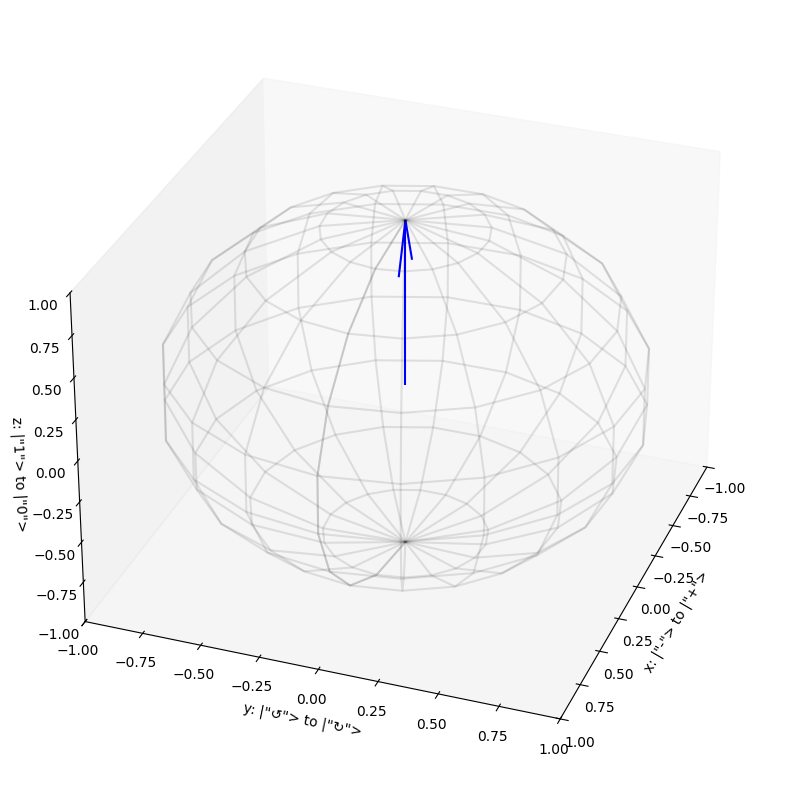

In [ ]:
plot_bloch(zero_qubit)

<Axes3D: xlabel='x: |"-"> to |"+">', ylabel='y: |"↺"> to |"↻">', zlabel='z: |"1"> to |"0">'>

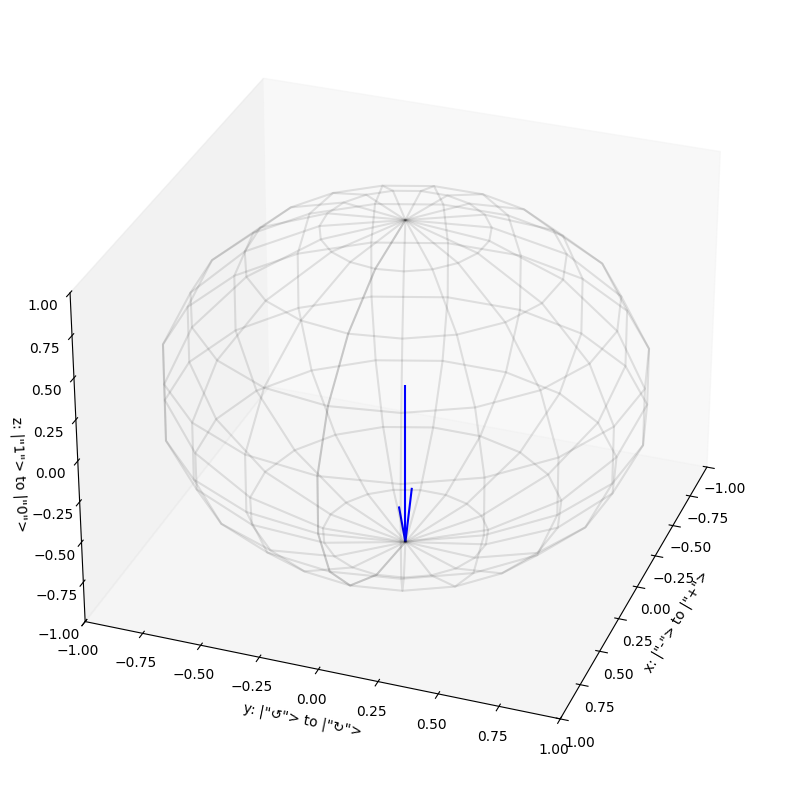

In [ ]:
plot_bloch(one_qubit)

Suppose we choose an arbitrary $\alpha$ and $\beta$ pair? Recall the restriction that $\alpha^2 + \beta^2$ must equal 1.

<Axes3D: xlabel='x: |"-"> to |"+">', ylabel='y: |"↺"> to |"↻">', zlabel='z: |"1"> to |"0">'>

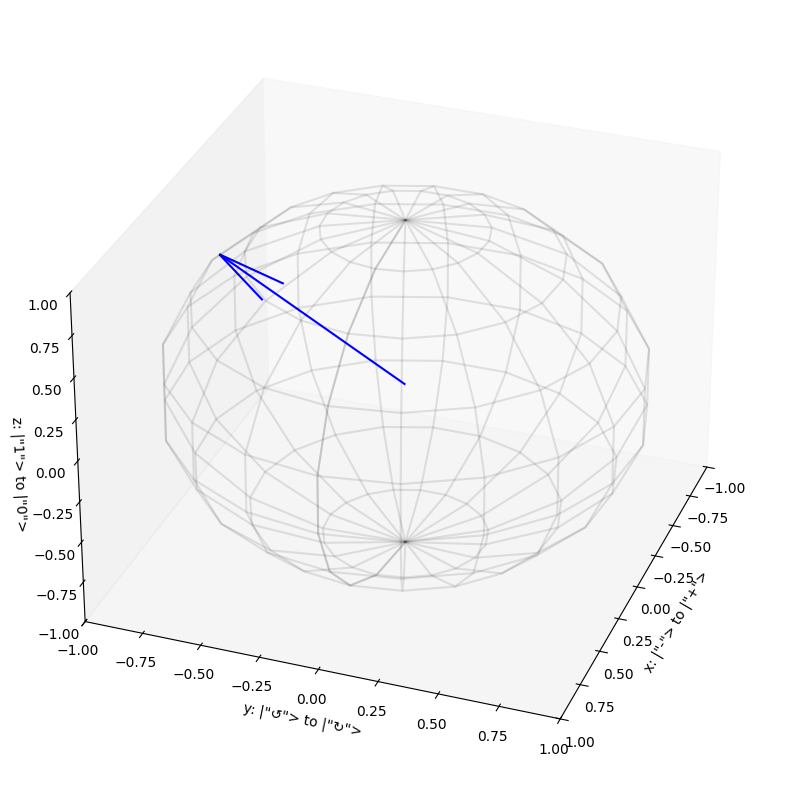

In [ ]:
eighty_twenty_qubit = np.sqrt(0.8)*zero_qubit - i_ * np.sqrt(0.2)*one_qubit
plot_bloch(eighty_twenty_qubit)

**Exercise:** Play with this code and draw some new qubits. Recall that:

$$
\alpha^2 + \beta^2 = 1
$$

really means

$$
\alpha^* \alpha + \beta^* \beta = 1
$$

where $\alpha^*$ is the _complex conjugate_ of $\alpha$. Here, that just means $i \to -i$, so

$$
(2 + 3i)^* = 2 - 3i
$$

etc.

### Measurement

Measurement is a two-step process - first we must choose a _basis_, and second we choose what we are measuring. The measurement itself will always give us a state in that basis.

An example of a basis is the "0/1-z" basis we've been implicitly using so far. (The "computational basis.") When we make a measurement, we "collapse the wave function". This means that if our original state was in a superposition, it no longer is. Measured states cease to be in superposition and they remain in the state they collapsed to no matter how many addition measurements we perform. The _probability_ a measurement producing a state is equal to the square of the amplitude of that state.

So, if our initial state is
$$
\psi = \sqrt{0.8} |0\rangle + \sqrt{0.2} |1\rangle
$$
we have an 80% chance of measureing $|0\rangle$ and a 20% chance of measuring $|1\rangle$ and every subsequent measurement will give the same answer - after the measurement the superposition is destroyed and we no longer have a probabilistic state.

Anyway, quantum mechanics is weird! We don't have time to go into how this was discovered, but you can read about it [on your own time](https://en.wikipedia.org/wiki/Stern%E2%80%93Gerlach_experiment)...

## Quantum circuits - lines and gates

### Special rules

Quantum circuits are composed of data lines and gates, like classical circuits, but there are some differences:

* We can't split lines (no implict copying) in a quantum circuit.

* Quantum gates are [unitary](https://en.wikipedia.org/wiki/Unitary_operator). This means quantum circuits are _reversible_, which means we can't have, e.g. classical-`AND` where it isn't clear how to run the circuit "backwards." It also means the gates are _norm preserving_.

Here is a quantum circuit:

<img src="images/epr-circuit.png" height="350">

We'll build this circuit in code later and explain the symbols. The `H` and the cross-bar both represent _quantum gates_ (the analog of our classical logic gates above). The `H` is acting on one qubit while the cross-bar is acting on two. This circuit is actually creating a _Bell pair_.

### Gates are linear operators

Linear algebra is the foundation of quantum computing. (It is the foundation of a _lot_ of things.)

We can represent quantum gates with _matrices_. Acting with a gate is equivalent to multiplying a state vector with a matrix.

For single qubits, these gates are $2 \times 2$ _Unitary matrices_.

First, we need to know how to take the _dot product_ of two vectors:

$$\begin{split}
A =& \begin{pmatrix} a_1 \\ a_2 \end{pmatrix};~ B = \begin{pmatrix} b_1 \\ b_2 \end{pmatrix} \\
A \cdot B =&~ a_1 \times b_1 + a_2 \times b_2
\end{split}$$

The dot product is used to define the _norm_, or length, of a vector:

$$\rightarrow |A| = \sqrt{A \cdot A} = \sqrt{a_{1}^2 + a_{2}^2}$$

This should actually look familiar...

<img src="images/pythag.png" height=400>

We often express inner products using the "bra-ket" ("bracket") notation:

$$
A \cdot B = \langle A | B \rangle
$$

$| 0 \rangle$ and $| 1 \rangle$ are _orthonormal_, which means:

$$
\begin{split}
\langle 0 | 0 \rangle =&~ \langle 1 | 1 \rangle = 1 \\
\langle 0 | 1 \rangle =&~ \langle 0 | 1 \rangle = 0
\end{split}
$$

And therefore, for $|\psi\rangle = \alpha |0\rangle + \beta |1\rangle$:


$$
\begin{split}
\langle \psi | \psi \rangle =&~ \left(\alpha \langle 0| + \beta \langle 1|\right) \left(\alpha |0\rangle + \beta |1\rangle \right) \\
=&~ \alpha^2 \langle 0 | 0 \rangle + \alpha \beta \left( \langle 0 | 1 \rangle + \langle 1 | 0 \rangle \right) + \beta^2 \langle 1 | 1 \rangle \\
=&~ \alpha^2 + \beta^2
\end{split}
$$

Since we know $\langle \psi | \psi \rangle = 1$, this is another way of expressing the normalization condition $\alpha^2 + \beta^2 = 1$.

Next, we need to understand matrix multiplication. Essentially, we dot each column vector of the second matrix (or vector) with each row of the first matrix (imagine picking the column up and "dropping it" on each row). We will only worry about 2x2 matrices and 2x1 vectors here, e.g.

$$
\begin{pmatrix} a_{11} & a_{12} \\ a_{21} & a_{22} \end{pmatrix} \begin{pmatrix} b_{1} \\ b_{2} \end{pmatrix} = \begin{pmatrix} a_{11} b_1 + a_{12} b_2 \\ a_{21} b_1 + a_{22} b_2 \end{pmatrix}
$$

Note that the output shape is 2x1. In general, if we multiply a $MxN$ matrix by an $NxP$ matrix, the output is $MxP$. So, $(2x2)(2x1) \rightarrow (2x1)$. This has all sorts of consequences (we can't multiply matrices of arbitrary shape and the order of multiplication matters, for example).

Can you think of a way states might operate on gates?

**Exercise:** Multiply

$$
\begin{pmatrix} 3 & 2 \\ 4 & -1 \end{pmatrix} \begin{pmatrix} 3 \\ 5 \end{pmatrix}
$$

### Multiple qubits

We describe multiple bits with state vectors as well.  An example multi-qubit state is:

$$
x = |0\rangle |1\rangle  |1\rangle |0\rangle |1\rangle = |01101\rangle
$$

We describe a two-bit classical system with one number - it is definitely "00" or "01", etc. But a quantum system may have a non-zero _amplitude_ in all of the possible states. Superpositon means the mathematical space these vectors span grows like $2^n$, where $n$ is the number of qubits. So for two qubits:

$$
\psi = a|00\rangle + b|01\rangle + c|10\rangle + d|11\rangle
$$

This requires keeping track of four (complex!) numbers (modulo constraints). For a two-qubit system, this is no problem, but, for example, a molecule in a chemistry problem might require hundreds of qubits to describe. So...

In [ ]:
pretty_print_number(2**200)

1606938044258990275541962092341162602522202993782792835301376


Of course, there is still a normalization condition on these terms. For example:

$$
\psi = \frac{1}{\sqrt{2}} \left( |001\rangle + |110\rangle \right)
$$

The sum of the squares of the coefficients is 1. This is _always_ the case for a valid quantum state.

Note that here, we have _one state_ that is a combination of values. Based on this _wavefunction_, we cannot say the left-most bit of the register is definitively a 0 or a 1. It is a combination. You might think - well, it is one or the other but we just don't know. This would imply the existence of _hidden variables_ in quantum mechanics. It is beyond the scope of this lecture to handle hidden variables, but there are definitive physical experiments you may conduct that show there are no hidden variables. A quantum state really can be a combination of states.

### Tensor products

How do we actually write the state vector for multi-qubit states? We need to take the _tensor product_ of the qubits, e.g.

$$
|\alpha\rangle |\beta\rangle \equiv |\alpha\beta\rangle \equiv |\alpha\rangle \otimes |\beta\rangle .
$$

_This is not the same as a dot or cross-product. It has different rules!_ In particular, we need a multiplication operation that takes two two-element vectors and makes a four-element vector. Three qubits should combine to make an eight-element vector.

The clearest way to show how the tensor product works is with an example:

$$
\begin{pmatrix} a \\ b \end{pmatrix} \otimes \begin{pmatrix} c \\ d \end{pmatrix} =  
\begin{pmatrix} a \begin{pmatrix} c \\ d \end{pmatrix} \\ b \begin{pmatrix}  c \\ d \end{pmatrix} \end{pmatrix} =
\begin{pmatrix} ac \\ ad \\ bc \\ bd \end{pmatrix}
$$

So,

$$
|0\rangle |0\rangle =
\begin{pmatrix} 1 \\ 0 \end{pmatrix} \otimes \begin{pmatrix} 1 \\ 0 \end{pmatrix} =  
\begin{pmatrix} 1 \begin{pmatrix} 1 \\ 0 \end{pmatrix} \\ 0 \begin{pmatrix}  1 \\ 0 \end{pmatrix} \end{pmatrix} =
\begin{pmatrix} 1 \\ 0 \\ 0 \\ 0 \end{pmatrix} =
|00\rangle
$$

This generalizes to higher dimensions in the "obvious" way, e.g.

$$
\begin{pmatrix} a_1 & b_1 \\ c_1 & d_1 \end{pmatrix} \otimes \begin{pmatrix} a_2 & b_2 \\ c_2 & d_2 \end{pmatrix} =  
\begin{pmatrix} a_1 \begin{pmatrix} a_2 & b_2 \\ c_2 & d_2 \end{pmatrix} & b_1 \begin{pmatrix} a_2 & b_2 \\ c_2 & d_2 \end{pmatrix} \\ c_1 \begin{pmatrix} a_2 & b_2 \\ c_2 & d_2 \end{pmatrix} & d_2 \begin{pmatrix} a_2 & b_2 \\ c_2 & d_2 \end{pmatrix} \end{pmatrix} =
\begin{pmatrix}
a_1 a_2 & a_1 b_2 & b_1 a_2 & b_1 b_2 \\
a_1 c_2 & a_1 d_2 & b_1 c_2 & b_1 d_2 \\
c_1 a_2 & c_1 b_2 & d_1 a_2 & d_1 b_2 \\
c_1 c_2 & c_1 d_2 & d_1 c_2 & d_1 d_2 \\
\end{pmatrix}
$$

**Exercise:** work out $|0\rangle \otimes |1\rangle$ and $|1\rangle \otimes |1\rangle$

<img src="images/giphy_2.gif">

### Quantum Gates

One example of a valid quantum gate is the _Not_ gate, also called the _X_ gate:

$$
X = \begin{pmatrix} 0 & 1 \\ 1 & 0 \end{pmatrix}
$$

Multiple gate operations in sequence are equivalent to multiplying the matrices in order (the order matters).

If we write it out, we see the Not gate flips one computational basis state to the other:

$$
X |0\rangle = \begin{pmatrix} 0 & 1 \\ 1 & 0 \end{pmatrix} \begin{pmatrix} 1 \\ 0 \end{pmatrix} = \begin{pmatrix} 0 \\ 1 \end{pmatrix} = |1\rangle
$$

Note that this imples $XX = I$. Two applications of $X$ bring us back to the identity.

$$
\begin{pmatrix} 0 & 1 \\ 1 & 0 \end{pmatrix} \begin{pmatrix} 0 & 1 \\ 1 & 0 \end{pmatrix} = \begin{pmatrix} 1 & 0 \\ 0 & 1 \end{pmatrix}
$$

Another example of a valid quantum gate is the _Y_ gate:

$$
Y = \begin{pmatrix} 0 & -i \\ i & 0 \end{pmatrix}
$$

Note that $XY$ is not the same as $YX$:

$$
XY = \begin{pmatrix} 0 & 1 \\ 1 & 0 \end{pmatrix} \begin{pmatrix} 0 & -i \\ i & 0 \end{pmatrix} = \begin{pmatrix} i & 0 \\ 0 & -i \end{pmatrix}
$$

$$
YX = \begin{pmatrix} 0 & -i \\ i & 0 \end{pmatrix} \begin{pmatrix} 0 & 1 \\ 1 & 0 \end{pmatrix} = \begin{pmatrix} -i & 0 \\ 0 & i \end{pmatrix}
$$

With what we've seen so far and a result like this, you should be able to work out how to multiply a pair of 2x2 matrices. (Or $NxN$ for that matter, but in practice, once we go over 3x3, we almost always use a computer.)

Another important operator is the _Hadamard_ gate. It rotates computational basis state vectors into superpositions:

$$
H = \frac{1}{\sqrt{2}} \begin{pmatrix} 1 & 1 \\ 1 & -1 \end{pmatrix}
$$

$$
H \psi = \frac{1}{\sqrt{2}} \begin{pmatrix} 1 & 1 \\ 1 & -1 \end{pmatrix} \times \begin{pmatrix} 1 \\ 0 \end{pmatrix} = \frac{1}{\sqrt{2}} \begin{pmatrix} 1 \\ 1 \end{pmatrix}
$$

$$
\begin{split}
H |0\rangle =&~ \frac{1}{\sqrt{2}} \left(|0\rangle + |1\rangle \right) \equiv |+\rangle  \\
H |1\rangle =&~ \frac{1}{\sqrt{2}} \left(|0\rangle - |1\rangle \right) \equiv |-\rangle  \\
\end{split}
$$

Note that like $X$, $H$ is also its own inverse, such that $HH = I$.

**Exercise:** Work out $HH$ to prove $HH = I$.

<Axes3D: xlabel='x: |"-"> to |"+">', ylabel='y: |"↺"> to |"↻">', zlabel='z: |"1"> to |"0">'>

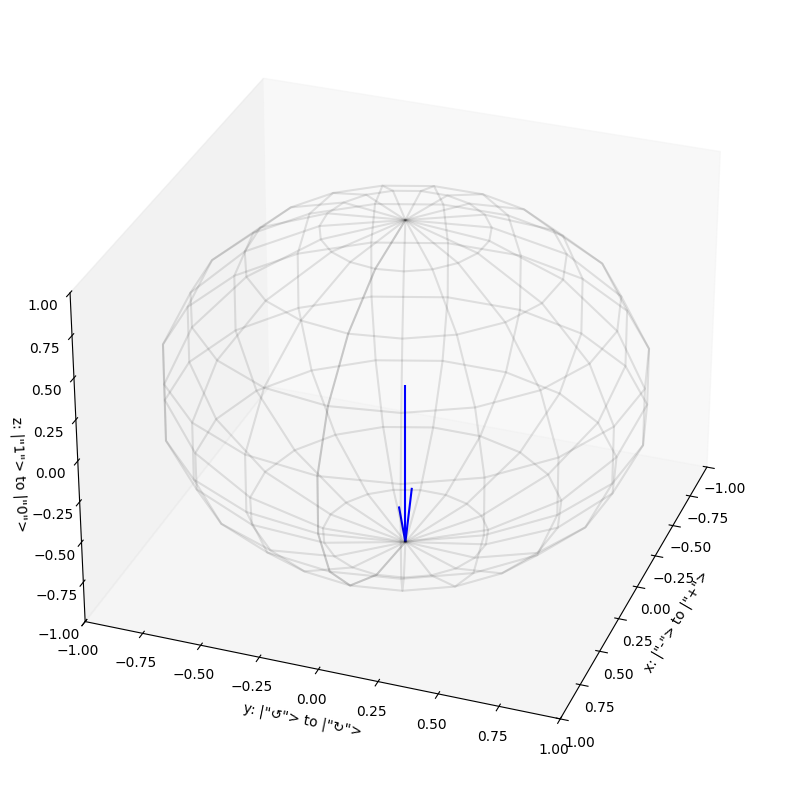

In [ ]:
plot_bloch(X * zero_qubit)

<Axes3D: xlabel='x: |"-"> to |"+">', ylabel='y: |"↺"> to |"↻">', zlabel='z: |"1"> to |"0">'>

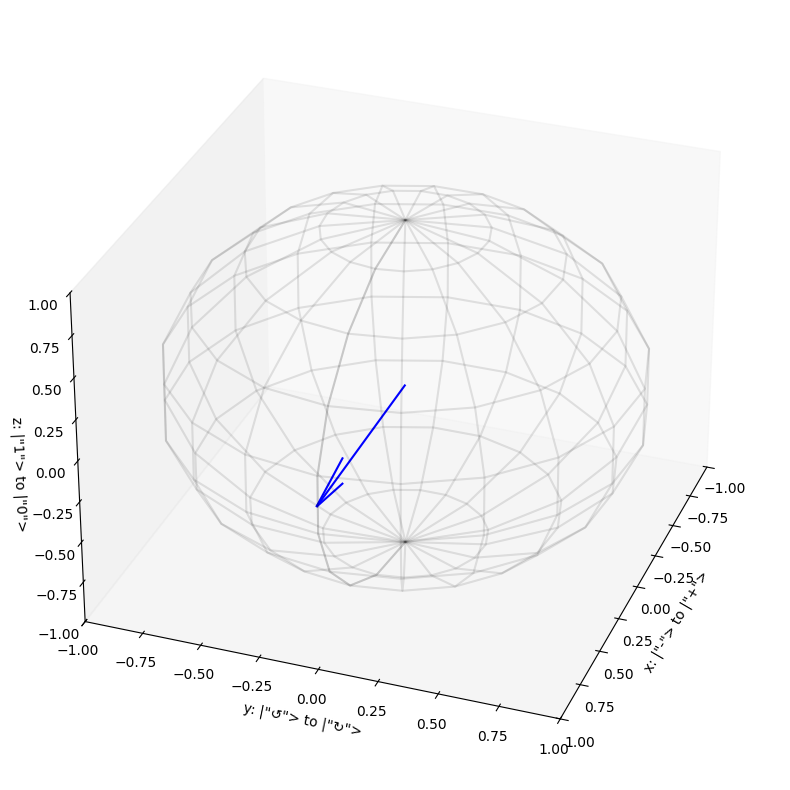

In [ ]:
plot_bloch(H * zero_qubit)

<Axes3D: xlabel='x: |"-"> to |"+">', ylabel='y: |"↺"> to |"↻">', zlabel='z: |"1"> to |"0">'>

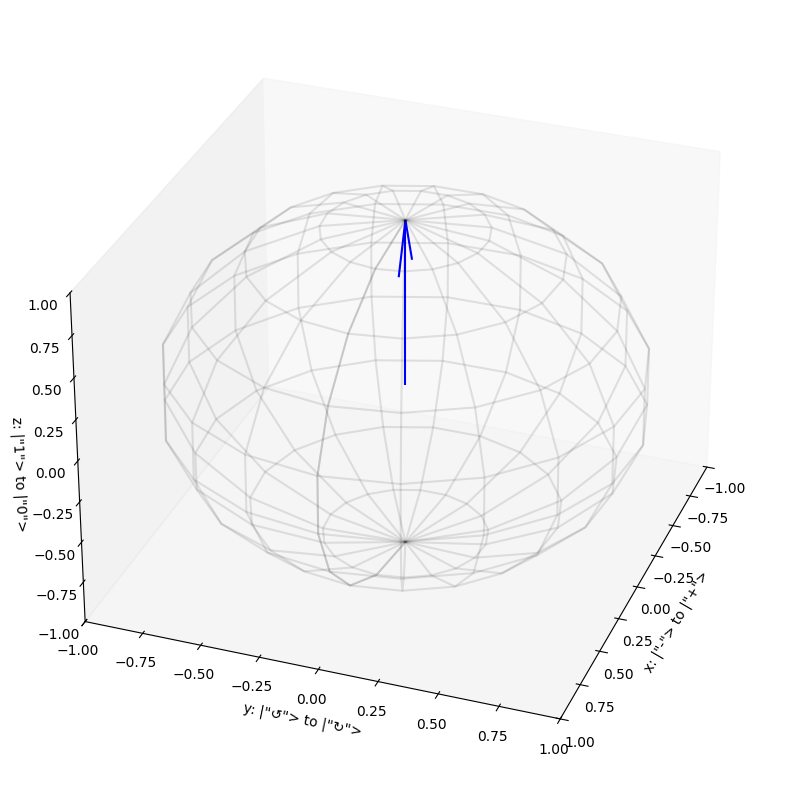

In [ ]:
plot_bloch(H * H * zero_qubit)

### Two-qubit gates

The gate for a two qubit state is a 4x4 matrix. One important two qubit gate is the CNOT, or _Controlled Not_ gate. This gate applies a Not to the second qubit in the pair, but only if the first qubit is in the $|1\rangle$ state. The CNOT gate looks like:

$$
\begin{pmatrix}
1 & 0 & 0 & 0 \\
0 & 1 & 0 & 0 \\
0 & 0 & 0 & 1 \\
0 & 0 & 1 & 0 \\
\end{pmatrix}
$$

Presented like this, the matrix doesn't make much sense, but look at how two-qubit state vectors are written:

$$
|00\rangle =
\begin{pmatrix}
1 \\
0 \\
0 \\
0 \\
\end{pmatrix},
|01\rangle =
\begin{pmatrix}
0 \\
1 \\
0 \\
0 \\
\end{pmatrix},
|10\rangle =
\begin{pmatrix}
0 \\
0 \\
1 \\
0 \\
\end{pmatrix},
|11\rangle =
\begin{pmatrix}
0 \\
0 \\
0 \\
1 \\
\end{pmatrix},
$$

If you stare at that long enough and think back to the rules we presented for matrix multiplication, you should be able to convince yourself that the CNOT only changes the state of vectors where the first qubit is in state $|1\rangle$ and its action is to flip the state of the second qubit.

The CNOT gate is important because it lets us generate _entanglement_.

### Bell pairs and entanglement

Along with superposition, one of the most important defining features of quantum states is _entanglement_. Entanglement occurs when we produce multi-qubit states that _cannot be decomposed into a simple product of single-qubit states_.

Many multi-qubit quantum states _may_ be written as the decomposition of single qubit states. For example, $|00\rangle$:

$$
\begin{pmatrix} 1 \\ 0 \\ 0 \\ 0 \end{pmatrix} = |00\rangle = |0\rangle \otimes |0\rangle
$$

This is just a fancy way of saying the state $|00\rangle$ is made up of two individual qubits in the $|0\rangle$ state sitting next to each other.

All classical states may be written as decompositions in this way, but there are quantum states that cannot be decomposed. We call these states _entangled_. For example, the state

$$
\frac{1}{\sqrt{2}} \left( |00\rangle + |11\rangle \right) =
\frac{1}{\sqrt{2}} \left(
    \begin{pmatrix} 1 \\ 0 \\ 0 \\ 0 \end{pmatrix} +
    \begin{pmatrix} 0 \\ 0 \\ 0 \\ 1 \end{pmatrix}
    \right) =
\frac{1}{\sqrt{2}} \begin{pmatrix} 1 \\ 0 \\ 0 \\ 1 \end{pmatrix}
$$

cannot be broken down into a tensor product of single qubit states. We happen to call two qubits in this particular state a "Bell pair". (There are actually four different Bell pairs and they form a _basis_.)

**Exercise:** Try to find a tensor product of two single qubit states that produces a Bell pair. You won't find one! See if you can prove it _isn't possible_ to produce the state that way.

**Exercise:** Can you find the three other Bell basis states? Hint - we get the first one by operating on $|00\rangle$ with the Bell circuit.

### No cloning!

<img src="images/giphy_6.gif">

(We don't mean that kind of clone...)

One last thing before we start wrting quantum circuits. A very important property of qubits is - we can't copy them! (In general.) This is a consquence of something called the [no cloning theorem](https://en.wikipedia.org/wiki/No-cloning_theorem).

Of course, if you know your qubit is in one of the basis states (after a measurement for example), you can easily "copy" it by putting another qubit into that state, but you can't copy an arbitrary qubit.

Suppose we *did* have a unitary operator that could clone a state. This means we have some operator $U$ such that $U|\psi\rangle |0\rangle = |\psi\rangle |\psi\rangle$. This can only be true if $|\psi\rangle$ is $|0\rangle$ or $|1\rangle$. Everything hinges on the fact our operator is _unitary_ (which means it can't change the norm of our state).

Here's a quick proof:

$$
\begin{split}
\langle \phi | \psi \rangle \langle 0 | 0 \rangle =&~ \langle \phi | \langle 0| | \psi \rangle | 0 \rangle \\
=&~ \langle \phi | \langle 0| U^{\dagger} U | \psi \rangle | 0 \rangle \\
=&~ \langle \phi | \psi \rangle \langle \phi | \psi \rangle \\
=&~ \left( \langle \phi | \psi \rangle \right)^2
\end{split}
$$

This is only true if $\langle \phi | \psi \rangle$ is 0 or 1.

## QASM - Quantum Assembly Language

Okay, at long last we can start writing some quantum _programs_.

<img src="images/giphy_3.gif">

Let's consider a diagram for the simple circuit - Hadamard on a single qubit, followed by measurement:

<img src="images/HandMeasure.png" alt="Hadamard and measure circuit" height="350">

How do we write a quantum program to run (simulate) this circuit?

[QASM](https://en.wikipedia.org/wiki/OpenQASM) is a "low-level" way of writing quantum programs. Because it is low-level, it lacks many of the abstractions that make writing very large programs convenient. But, on the other hand, because it is low level it is simple to see what is going on in short, simple programs without requiring us to learn a new library or high-level programming language. You can read much more about QASM in this [acadmic paper](https://arxiv.org/abs/1707.03429) from IBM.

In [ ]:
#@title "Python function to read and run QASM strings [Run me!]" { display-mode: "form" }
def run_qasm_string(qasm_str, verbose=True, shots=1024):
    qc = QuantumCircuit.from_qasm_str(qasm_str=qasm_str)
    backend = Aer.get_backend("qasm_simulator")
    qc = qiskit.compiler.transpile(qc, backend=backend)
    job = backend.run(qc, shots=shots)
    result = job.result()
    if verbose:
        print(result.get_counts())
    return result

To create a quantum program in QASM, we will write a special Python string that can cover multiple lines. We will do this like so:

```
quantum_program_string_name = """
--- code goes here ---
"""
```

This construct - putting a string between pairs of triple quotes - makes it possible to write a nice, reasy to read multi-line string.

For the program itself, first we need some "boilerplate" in our string:

```
OPENQASM 2.0;
include "qelib1.inc";
```

We just have to put there every time. Don't worry too much about it.

Next, we create a quantum register - `qreg` - this is the part of the program that "allocates" a qubit. We also create a classical register - `creg` - this is the part of the program that stores the value of our _measurement_ of the qubit.

Then, we apply the Hadamard gate to our qubit: `h q[0]`. Note that we are addressing the first element of the array of qubits in our register (which had length 1) by using the `0` in the brackets. Basically, the `[]`'s let us store many values under one variable _and_ give us a way to "look up" values inside that array. Finally, we'll measure the outcome.

In [ ]:
random_bit_qasm_str = """
OPENQASM 2.0;
include "qelib1.inc";

qreg q[1];
creg c[1];
h q[0];
measure q[0] -> c[0];
"""

In [ ]:
_ = run_qasm_string(random_bit_qasm_str)

{'1': 532, '0': 492}


We created a `|+>` state by rotating our qubit around the Bloch sphere. This state is a _superposition_ of the `|0>` and `|1>` states. Since we are measuring in the computational basis, we can only measure either `|0>` or `|1>` as an outcome.

What we find is a _probabilisitc_ result. About half the time we measure `|0>` and about half the time we measure `|1>`. The more times we repeat the experiment, the closer the fraction will be to 50/50. We're using the default 1,024 "shots" or experiment repetitions throghout this notebook (and we use 1,024 instead of 1,000 because we're computing geeks and like powers of two ^_^).

Let's look at one more - let's create the Bell pair we showed earlier:

<img src="images/epr-circuit.png" height="350">

In [ ]:
bell_qasm_str = """
OPENQASM 2.0;
include "qelib1.inc";

qreg q[2];
creg c[2];
h q[0];
cx q[0],q[1];
measure q[0] -> c[0];
measure q[1] -> c[1];
"""

In [ ]:
_ = run_qasm_string(bell_qasm_str)

{'00': 530, '11': 494}


We can verify this the hard way with linear algebra also. One key point - the first step, where we act with `H` on qubit 0 is also **really** a two qubit operation - it is $H \otimes I$ - the _tensor product_ of `H` and `I` (the identity). This is because all the way through our calculation above, our full wavefunction is a four-element vector. It just happens to start in a separable state.  The full linear algebra looks like this...

$$
(CNOT)(H_{0} \otimes I_{1})|\psi\rangle =
\begin{pmatrix}
1 & 0 & 0 & 0 \\
0 & 1 & 0 & 0 \\
0 & 0 & 0 & 1 \\
0 & 0 & 1 & 0 \\
\end{pmatrix}
\frac{1}{\sqrt{2}} \begin{pmatrix}
1 & 0 & 1 & 0 \\
0 & 1 & 0 & 1 \\
1 & 0 & -1 & 0 \\
0 & 1 & 0 & -1 \\
\end{pmatrix}
\begin{pmatrix}
1 \\
0 \\
0 \\
0 \\
\end{pmatrix}
= \frac{1}{\sqrt{2}} \begin{pmatrix} 1 \\ 0 \\ 0 \\ 1 \end{pmatrix}
$$

Note the order of operations! We first act on the vector using the $H \otimes I$ matrix, and then using the `CNOT`. You can't swap the order of the matrices! That is a different circuit.

Everyone should multiply all of this out once to see that it works, but really, multiplying large matrices by hand is tedious and not illuminating so nobody does it (although you may have to in a class someday). Anyway, people use software to do this in the real world.

## IBM Quantum Experience

Writing QASM is a fine way to run simple programs, but it can be a tricky way to get an intuition for what gates do and how the wavefunction evolves through a circuit, etc.

Let's look at another tool from IBM - [The IBM Quantum Experience](https://quantum-computing.ibm.com). In order to use the Quantum Experience, you need to create an IBMId. This is a free account that requires an email address and (as of 2024) proof of citizenship (quantum is a big deal in the defense sector now).

With this account, you will have access to a cloud platform that provides Jupyter notebooks for learning Qiskit (IBM's Python library for writing complex quantum circuits) and a "Circuit Composer" that provides a visual GUI for building a circuit that reminds me a bit of writing music. You can simulate the circuit and inspect the wavefunction at each step. You can even run programs on a real quantum computer (although you may have to wait a while for the "jobs" in line ahead of you to run).

<img src="images/IBM-Quantum-Experience-Example.png">

**Note** - the "Q-sphere" they are showing here is not the same thing as a Bloch sphere! You can read about it [here](https://quantum-computing.ibm.com/docs/iqx/visualizations#q-sphere-view). We aren't going to discuss it now, but it is a way of visualizing the state of more than one qubit (the Bloch sphere works for one and only one qubit).

The circuit composer does several very nice things for us. It provides a set of [visualization tools](https://quantum-computing.ibm.com/docs/iqx/visualizations) to help us understand the evolution of a (small) number of qubits. It lets us write circuits using QASM and the circuit display will reflect that code. It also lets us build a circuit graphically and then provides the QASM for that circuit.

We can even run the circuit on a real quantum computer! Here are the results from running on one of IBM's 5 qubit machines ("Athens"):

<img src="images/Bell-on-hardware.png" height=500>

Note that the result is not _exactly_ what we predicted. There is a small chance of a $|01\rangle$ or $|10\rangle$ state. This is due to _noise_ on the quantum computer. Noise is a complex topic and we won't get into it in depth. The simple way to think about it is that it is very hard to isolate the computer from the environment, and very hard to make our gate operations perfect (they're microwave radio waves pointed at little bits of metal, after all). Dealing with noise (mitigation, correction, device improvements, etc.) is one of the dominant activities in quantum computing research. Things aren't perfect yet, but we've come a long way, with progress really accelerating over the last decade.

## A practical quantum application

Based on "Quantum Spy Hunter" from the book [Programming Quantum Computers](https://www.oreilly.com/library/view/programming-quantum-computers/9781492039679/) by O'Reilly.

Suppose Alice and Bob share a pair of communication channels. One can transmit classical bits and one can transmit qubits. Practically this is accomplished using an algorithm called [quantum teleportation](https://en.wikipedia.org/wiki/Quantum_teleportation). By the way, quantum teleportation is not science fiction, it is a real thing [we do at Fermilab!](https://news.fnal.gov/2020/12/fermilab-and-partners-achieve-sustained-high-fidelity-quantum-teleportation/) Sadly though we can't use it to beam ourselves anywehere...

<img src="images/giphy_7.gif">

Alice would like to send Bob some quantum information, but she fears there may be eavesdroppers on the channel. Therefore, they have agreed on an exchange protocol. Before sending sensitive data, they will send some "spy sniffer" qubits and some classical bits. The classical bits will follow an agreed upon code for a set of operations to perform on the qubits. These operations will establish whether the qubit was tampered with. Note that Alice and Bob had to agree on how to interpret these classical bits in advance, but afterwards, all of their information exchange is fully "public" (takes place on these channels).

<img src="images/nospyhunter.png">


In [ ]:
pp = pprint.PrettyPrinter(indent=4)

In [ ]:
no_spy_hunter_string = """
OPENQASM 2.0;
include "qelib1.inc";

// set up quantum registers - Alice, Bob, and the fiber
qreg alice[1];
qreg fiber[1];
qreg bob[1];

// set up classical registers
creg ahad[1];
creg aval[1];
creg fval[1];
creg bval[1];

// generate two random bits with Alice's QPU
reset alice[0];
h alice[0];
measure alice[0] -> ahad[0];
reset alice[0];
h alice[0];
measure alice[0] -> aval[0];

// prepare Alice's qubit - randomly create one of
// |0>, |1>, |+>, or |->, but don't say which...
reset alice[0];
if(aval==1) x alice[0];
if(ahad==1) h alice[0];

// send the qubit
swap alice[0],fiber[0];
// receive the qubit
swap fiber[0],bob[0];

// Alice sends ahad and aval to Bob.
// read the transmitted qubit
if(ahad==1) h bob[0];
if(aval==1) x bob[0];

measure bob[0] -> bval[0];
"""

In [ ]:
result = run_qasm_string(no_spy_hunter_string, verbose=False)
pp.pprint(result.get_counts())
# read: 'bval fval aval ahad'

{'0 0 0 0': 275, '0 0 0 1': 243, '0 0 1 0': 270, '0 0 1 1': 236}


/usr/local/lib/python3.11/dist-packages/qiskit/circuit/quantumcircuit.py:4120: FutureWarning: Conditioned gates in qasm2 will be loaded as an IfElseOp starting in Qiskit 2.0
  return qasm2.loads(


Interpretation: we always find '0' in Bob's measurement value (`bval`). This means he always knew the exactly correct sequence of gates to apply to de-scramble the qubit back to `|0>`. So, the qubit was never tampered with.

By the way - this is what this circuit looks like in the Circuit Composer:

<img src="images/No-Spy-Hunter.png">

Note - the QASM code has the comments taken out. Also, the spacing is a bit fiddly, but if you do it right, when you run the Inspector, it will step through the QASM code line-by-line in sync with the graphic circuit.

We can run the code on the Quantum Experience website (here, looking at a simulator) and view the output:

<img src="images/No-Spy-Hunter-Job.png">

It's what we expected.

Now, let's introduce a spy (traditionally named "Eve") and see what happens.

<img src="images/nospyhunter-eve.png">

Eve is able to capture data in flight and she has a fully functioning quantum lab, so she can create and measure qubits and send any information she would like on the channel. Eve's goal is to capture and store sensitive quantum information.

In [ ]:
spy_hunter_string = """
OPENQASM 2.0;
include "qelib1.inc";

// set up quantum registers - Alice, Bob, and the fiber
qreg alice[1];
qreg fiber[1];
qreg bob[1];

// set up classical registers
creg ahad[1];
creg aval[1];
creg fval[1];
creg bval[1];

// generate two random bits with Alice's QPU
reset alice[0];
h alice[0];
measure alice[0] -> ahad[0];
reset alice[0];
h alice[0];
measure alice[0] -> aval[0];

// prepare Alice's qubit - randomly create one of
// |0>, |1>, |+>, or |->, but don't say which...
reset alice[0];
if(aval==1) x alice[0];
if(ahad==1) h alice[0];

// send the qubit
swap alice[0],fiber[0];

// now a spy intercepts - can't see true quantum state,
// can only measure and try to replace the state.
barrier alice[0],fiber[0],bob[0];
measure fiber[0] -> fval[0];
reset fiber[0];
if(fval==1) x fiber[0];
barrier alice[0],fiber[0],bob[0];

// receive the qubit
swap fiber[0],bob[0];

// Alice sends ahad and aval to Bob. He
// inverts Alice's transformations and
// reads the transmitted qubit
if(ahad==1) h bob[0];
if(aval==1) x bob[0];

measure bob[0] -> bval[0];
"""

In [ ]:
result = run_qasm_string(spy_hunter_string, verbose=False)
pp.pprint(result.get_counts())
# read: 'bval fval aval ahad'

{   '0 0 0 0': 281,
    '0 0 0 1': 62,
    '0 0 1 1': 65,
    '0 1 0 1': 58,
    '0 1 1 0': 252,
    '0 1 1 1': 53,
    '1 0 0 1': 66,
    '1 0 1 1': 72,
    '1 1 0 1': 58,
    '1 1 1 1': 57}


/usr/local/lib/python3.11/dist-packages/qiskit/circuit/quantumcircuit.py:4120: FutureWarning: Conditioned gates in qasm2 will be loaded as an IfElseOp starting in Qiskit 2.0
  return qasm2.loads(


**Note** - if you try to run this program on quantum hardware, it will complain because we are conditioning based on some measurement outcomes. You'd need to break the code up to really run it on IBM's service. (They are working on mid-circuit measurement, so it _might_ work...)

The interpretation is subtle and requires walking through case-by-case. Remember Alice and Bob have agreed in advance to exchange classical bits that tell Bob which quantum gates to apply to the spy-sniffer qubit Alice has sent. Bob should get the `|0>` state if he has applied the correct gates to an undisturbed qubit. If Bob ever finds a `|1>`, he knows the qubit has been tampered with and someone is listening in on their communications.

<img src="images/giphy_8.gif" height=350>


Note that because quantum mechanics is _probabilistic_ there is no guarantee every spy-sniffer qubit will reveal eavesdropping!

* `0 0 0 0` - Alice doesn't apply an H or an X, sends `|0>`. Eve measures a 0, so she sends `|0>`. Bob gets '00' from Alice and doesn't apply any gates to `|0>` and measures a '0'. **Spy not caught.**
* `0 0 0 1` - Alice applies a Hadamard and sends `|+>`. Eve measures a 0 so she sends `|0>`. Bob gets '01' from Alice, so he applies a Hadamard to `|0>` and produces `|->`, but then measures a '0' (50/50 chance). **Spy not caught.**
* `0 0 1 1` - Alice applies X and H, and sends `|->`. Eve measures 0 and sends `|0>`. Bob gets '11' from Alice, so he applies a H and then an X and produces `|+>`, but then measures a '0' (50/50 chance). **Spy not caught.**
* `0 1 0 1` - Alice applies an H and sends `|+>`. Eve measures a '1', so she sends '|1>'. Bob gets '01' from Alice, so he applies an H and produces `|->`, but then measures a '0' (50/50 chance). **Spy not caught.**
* `0 1 1 0` - Alice applies and X and sends `|1>`. Eve measures `|1>` and sends `|1>`. Bob gets `10` from Alice, so applies an X to `|1>` and gets `|0>`. **Spy not caught.**
* `0 1 1 1` - Alices applies X and H and send `|->`.  Eve measures 1 and sends `|1>`. Bob gets '11' from Alice so he applies a H and then an X and produces `-|->`. He then measures a '0' (50/50 chance). **Spy not caught.**
* `1 0 0 1` - Alice applies an H and sends `|+>`. Eve measures 0 and so sends `|0>`. Bob gets '01' from Alice so he applies an H to produce `|+>` and measures a '1' (50/50 chance). **Spy is caught!**
* `1 0 1 1` - Alice applies X and H, and sends `|->`. Eve measures 0 and sends `|0>`. Bob gets '11' from Alice, so he applies a H and then an X and produces `|+>`, and then measures a '1' (50/50 chance). **Spy is caught!**
* `1 1 0 1` - Alice applies an H and sends `|+>`. Eve measures a '1', so she sends '|1>'. Bob gets '01' from Alice, so he applies an H and produces `|->`, and then measures a '1' (50/50 chance). **Spy is caught!**
* `1 1 1 1` - Alices applies X and H and send `|->`.  Eve measures 1 and sends `|1>`. Bob gets '11' from Alice so he applies a H and then an X and produces `-|->`. He then measures a '1' (50/50 chance). **Spy is caught!**

So, what was the chance of catching the spy with any given sniffer qubit? We can use some Python to query the _dictionary_ the IBM simulator returned to us:

In [ ]:
times_caught = 0
for i in result.get_counts().items():
    if i[0][0] == '1':
        times_caught += i[1]
print('The spy was caught {} times,'.format(times_caught))
prob_of_catching = times_caught / 1024.0
print('---> = {}% of the times we sent a spy-hunter qubit.'.format(prob_of_catching * 100))

The spy was caught 253 times,
---> = 24.70703125% of the times we sent a spy-hunter qubit.


So, if the spy has a roughly 25% chance of being caught with each spy-hunter qubit, how many spy-hunter qubits do Alice and Bob need to exchange? Theoretically, an infinite number, but suppose they were okay with a 99.999% chance of catching a spy. How many do they need to send?

It is easiest to solve this sort of probability problem not as what is the chance of 'one catch' plus 'two catches', etc., but rather as 100% minus the probability of 'no catches'. Imagine you sent one qubit, you have roughly 75% chance of missing the spy. If you send two, you have a 75% times 75% equals 56% chance of missing the spy, so a 44% chance of catching the spy. Every qubit you send reduces the chances of missing the spy, with the chance of the spy slipping through dropping by 3/4 with each qubit.

In [ ]:
threshold = 0.99999
prob_of_catching = 0.25   # exact probability, not our estimate

def F(x):
    return (1 - (1 - prob_of_catching)**x) - threshold

num_times = scipy.optimize.bisect(F, 1, 50); num_times

40.0196138982692

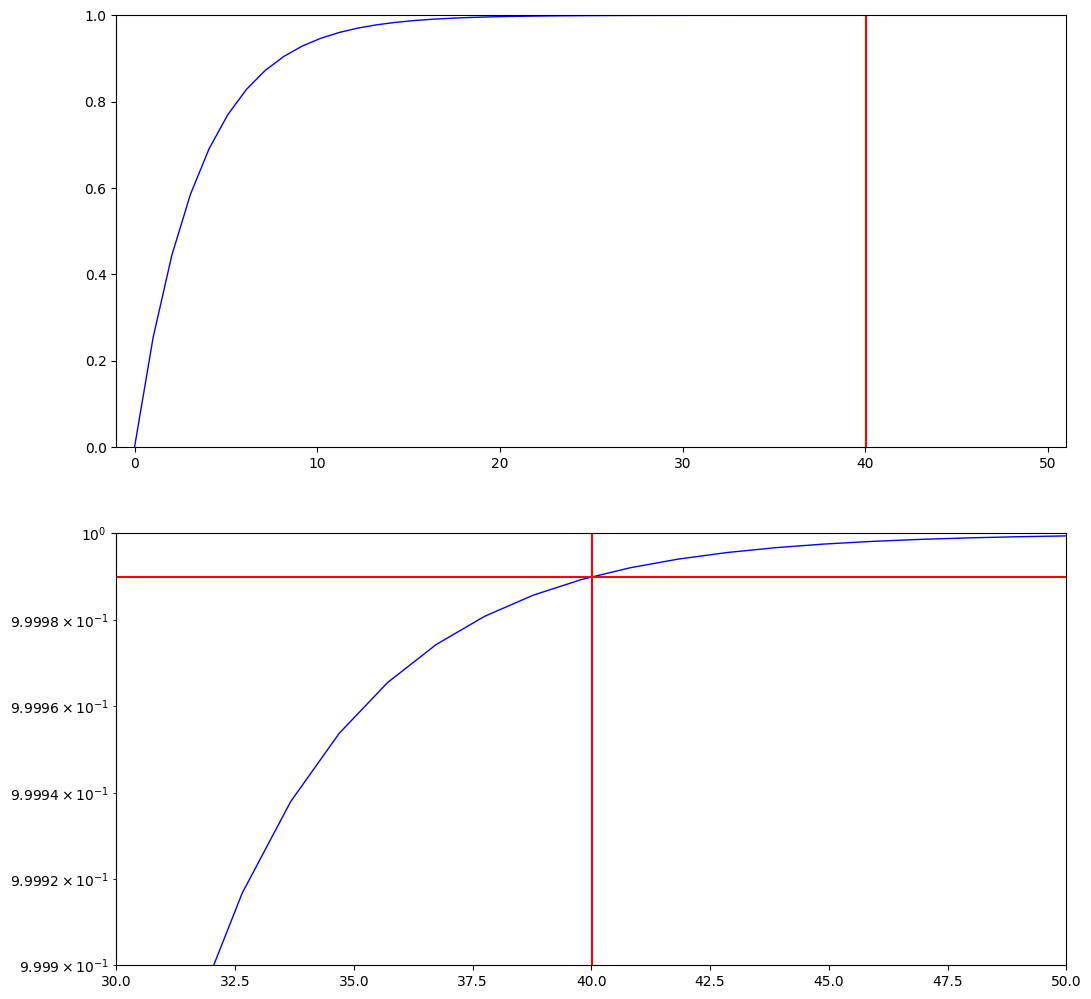

In [ ]:
x = np.linspace(0, 50)
y = 1 - (1 - prob_of_catching)**x
fig = plt.figure(figsize=(10, 10))
fig.subplots_adjust(bottom=0.025, left=0.025, top=0.975, right=0.975)

ax1 = plt.subplot(2, 1, 1)
plot1, = plt.plot(x, y, color='blue', linewidth=1)
ax1.set_xlim([-1, 51])
ax1.set_ylim([0, 1])
ax1.axvline(x=num_times, color='red')

ax2 = plt.subplot(2, 1, 2)
plot2, = plt.plot(x, y, color='blue', linewidth=1)
ax2.set_xlim([30, 50])
ax2.set_ylim([0.9999, 1])
ax2.set_yscale('log')
ax2.axhline(y=threshold, color='red')
ax2.axvline(x=num_times, color='red')

If you have a quantum communication channel this is a pretty cheap check to see if there are eavesdroppers. 2 classical bits plus 1 qubit, sent about 40 times. Note we don't even care if the classical channel is observed. Because Eve doesn't know what '00', '01', etc. _mean_, there is nothing she can do with that information. If you're worried she might guess, don't use common gates like `H` and `X`, but "rotate" them by some pre-agreed angle. Eve has to guess that angle (as a real number) **exactly**. (However, there is always some classical information that Alice and Bob have to agree on in advance and keep secret --- so maybe Eve's best bet is good old-fashioned human espionage.)

Also note - Eve has no way to predict the classical _sequence_ of 'xy' bits. Resolving the qubit is a truly random process. Most "random" computational processes are not actually random - they are pseudorandom and use generators that have patterns built in. Those patterns may be quite long, but they're there, and if Eve observed long enough, she could find a pattern. There is absolutely no pattern to the classical bits Alice is sending!